## Abstract


&nbsp;&nbsp;&nbsp;&nbsp;Le but de ce projet est de développer un réseau de neurones appelé U-Net, dont la structure en forme de U lui donne son nom, et de comparer ses performances à celles de réseaux plus simples. Nous souhaitons déterminer si, dans le cadre de la segmentation d'images biomédicales, il est nécessaire de développer des architectures aussi complexes pour obtenir des performances satisfaisantes.

&nbsp;&nbsp;&nbsp;&nbsp;Dans un premier temps, nous développerons le réseau U-Net, dont nous expliquerons la structure (encodeur, goulot d'étranglement, décodeur et skip connections) avant d'analyser ses performances. Nous en proposerons également une version simplifiée, plus compacte (trois niveaux de sous-échantillonnage, jusqu'à 512 filtres) et régularisée par des couches de BatchNormalization et de Dropout. Dans un second temps, nous développerons des solutions plus traditionnelles, telles qu'un réseau convolutionnel simple, un réseau ResNet et, enfin, un réseau simplifié inspiré d'architectures plus complexes, comme Inception.

&nbsp;&nbsp;&nbsp;&nbsp;Nous analyserons ici des images de mammographie afin d'entraîner nos réseaux à segmenter les régions présentant des caractéristiques suspectes pouvant être associées à un cancer du sein. Contrairement à une simple classification, qui consiste à déterminer si une image contient ou non un cancer, la segmentation permet d'identifier et de délimiter précisément les zones suspectes au niveau des pixels, en labellisant les pixels plutôt que l'image dans son ensemble. Elle offre ainsi une information spatiale plus détaillée, permettant de localiser les anomalies au sein de l'image afin de simplifier le travail d'un spécialiste.

&nbsp;&nbsp;&nbsp;&nbsp;Nous évaluerons les performances de nos modèles à l'aide de plusieurs métriques adaptées à la segmentation : la loss, l'accuracy, la precision, le recall, le score de Dice (ou F1 au niveau des pixels), l'IoU de la classe cancéreuse, le Mean IoU, ainsi que l'AUC ROC et l'AUC PR. L'accuracy seule étant trompeuse lorsque les pixels de fond sont très largement majoritaires, nous accorderons plus d'importance au Dice et à l'IoU, qui mesurent la qualité du recouvrement entre la zone prédite et la zone réelle, et à l'AUC PR, plus informative que l'AUC ROC lorsque la classe d'intérêt est minoritaire. Une attention particulière sera portée à la maximisation du recall, afin de limiter les faux négatifs, c'est-à-dire les régions cancéreuses qui ne seraient pas détectées par le modèle. Cet enjeu est particulièrement important dans le domaine médical, où l'absence de détection d'une anomalie peut avoir des conséquences significatives sur le diagnostic et la prise en charge des patientes. Ce recall devra néanmoins être mis en regard de la precision, afin de ne pas multiplier les fausses alertes qui alourdiraient le travail du spécialiste.

&nbsp;&nbsp;&nbsp;&nbsp;Afin de garantir la reproductibilité des résultats et la comparabilité des modèles, une seed globale est fixée pour l'ensemble du notebook.

# Partie 1 : Developpement du UNet

## Description du réseau

&nbsp;&nbsp;&nbsp;&nbsp; Le réseau U-Net est un réseau de neurones convolutif dont l'architecture repose sur deux parties complémentaires : un encodeur, qui réduit progressivement la résolution spatiale de l'image, et un décodeur, qui permet de reconstruire progressivement sa résolution initiale grâce à des convolutions transposées (up-convolutions).

&nbsp;&nbsp;&nbsp;&nbsp; L'encodeur est composé de quatre blocs successifs. Chacun de ces blocs contient deux couches de convolution de taille 3 × 3, suivies d'une fonction d'activation ReLU. À la fin de chaque bloc, une opération de max pooling de taille 2 × 2 est appliquée afin de réduire de moitié la résolution spatiale de l'image et d'extraire des caractéristiques de plus en plus abstraites.

&nbsp;&nbsp;&nbsp;&nbsp; Une particularité essentielle de l'architecture U-Net réside dans ses connexions de saut (skip connections). À la sortie de chaque bloc de l'encodeur, les caractéristiques extraites sont copiées puis recadrées (cropped) afin d'être transmises au bloc correspondant du décodeur. Ces connexions permettent de conserver les informations spatiales détaillées perdues lors de la réduction de résolution et de les réutiliser pendant la reconstruction.

&nbsp;&nbsp;&nbsp;&nbsp; Le bloc le plus profond du réseau, situé entre l'encodeur et le décodeur, constitue le point de transition de l'architecture. Il est composé de deux couches de convolution de taille 3 × 3, chacune suivie d'une fonction d'activation ReLU. Il permet d'extraire les caractéristiques les plus abstraites de l'image avant d'entamer la phase de reconstruction.

&nbsp;&nbsp;&nbsp;&nbsp; Le décodeur constitue la seconde partie du réseau. À chaque étage, la résolution spatiale est augmentée grâce à une convolution transposée (up-convolution) de taille 2 × 2. Les caractéristiques obtenues sont ensuite concaténées avec celles provenant de la connexion de saut correspondante de l'encodeur. Chaque bloc du décodeur est alors composé de deux couches de convolution de taille 3 × 3, suivies chacune d'une fonction d'activation ReLU.

&nbsp;&nbsp;&nbsp;&nbsp; Enfin, une dernière convolution 1 x 1 permet de projeter les caractéristiques obtenues sur le nombre de classes souhaité, afin d'attribuer à chaque pixel de l'image une classe et de produire ainsi la segmentation finale.

<p align="center">
    <img src="Unet.png"  width="800">
</p>

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns; sns.set(style="whitegrid")
from pathlib import Path

import os, io, re
import zipfile
from pathlib import Path
import tifffile
import imagecodecs

SEED = 2026

os.environ["PYTHONHASHSEED"] = str(SEED)
keras.utils.set_random_seed(SEED)           # fixe random, numpy et tensorflow d'un coup
tf.config.experimental.enable_op_determinism()  # force des opérations GPU déterministes

In [6]:
# --- Configuration ---------------------------------------------------------
DATA_DIR = Path(r"C:\Users\Antonin\Studies\Project\UNet_&_CNN\data\Kvasir-SEG")
IMAGE_DIR = DATA_DIR / "images"
LABEL_DIR = DATA_DIR / "masks"

INPUT_SIZE = 572
OUTPUT_SIZE = 388
VALIDATION_SIZE = 0.2
RANDOM_STATE = 42

CROP_START = (INPUT_SIZE - OUTPUT_SIZE) // 2
CROP_END = CROP_START + OUTPUT_SIZE


# --- Fonctions utilitaires -------------------------------------------------
def load_image(path: Path) -> np.ndarray:
    """Charge une image JPEG en niveaux de gris, redimensionnée et normalisée dans [0, 1]."""
    image = tf.io.decode_jpeg(tf.io.read_file(str(path)), channels=1)
    image = tf.image.resize(image, [INPUT_SIZE, INPUT_SIZE], method="bilinear")
    return (image / 255.0).numpy().astype(np.float32)


def load_mask(path: Path) -> np.ndarray:
    """Charge un masque binaire, redimensionné puis recadré au centre (taille de sortie de l'U-Net)."""
    mask = tf.io.decode_jpeg(tf.io.read_file(str(path)), channels=1)
    mask = tf.cast(mask > 127, tf.float32)
    mask = tf.image.resize(mask, [INPUT_SIZE, INPUT_SIZE], method="nearest")
    return mask.numpy()[CROP_START:CROP_END, CROP_START:CROP_END, 0].astype(np.uint8)


# --- Vérification des dossiers ---------------------------------------------
for directory in (IMAGE_DIR, LABEL_DIR):
    if not directory.is_dir():
        raise FileNotFoundError(f"Dossier introuvable : {directory.resolve()}")

# --- Listage des fichiers --------------------------------------------------
image_paths = sorted(IMAGE_DIR.glob("*.jpg"), key=lambda p: p.stem)
label_paths = {path.stem: path for path in LABEL_DIR.glob("*.jpg")}

if len(image_paths) < 2:
    raise ValueError("Il faut au moins deux images pour créer train et validation.")
if {p.stem for p in image_paths} != label_paths.keys():
    print(p.stem for p in image_paths)
    print(label_paths.keys())
    raise ValueError("Les noms des images et des masques ne correspondent pas.")

# --- Chargement Train ------------------------------------------------------------
X = np.stack([load_image(p) for p in image_paths])
y = np.stack([load_mask(label_paths[p.stem]) for p in image_paths])

# --- Split train+val / test (80/20 du X de base) ----------------------------
rng = np.random.default_rng(RANDOM_STATE)
indices = rng.permutation(len(X))

n_test = max(1, int(np.ceil(len(X) * 0.20)))
test_idx, trainval_idx = indices[:n_test], indices[n_test:]

# --- Split train / validation (80/20 du train) ------------------------------
# trainval_idx est déjà mélangé, pas besoin de re-permuter
n_val = max(1, int(np.ceil(len(trainval_idx) * 0.20)))
val_idx, train_idx = trainval_idx[:n_val], trainval_idx[n_val:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]


print(f"X_train : {X_train.shape} | y_train : {y_train.shape}")
print(f"X_val   : {X_val.shape} | y_val   : {y_val.shape}")
print(f"X_test  : {X_test.shape} | y_test  : {y_test.shape}")

X_train : (320, 572, 572, 1) | y_train : (320, 388, 388)
X_val   : (80, 572, 572, 1) | y_val   : (80, 388, 388)
X_test  : (100, 572, 572, 1) | y_test  : (100, 388, 388)


In [7]:
import tensorflow.keras.backend as K

def dice_loss(y_true, y_pred):
    """"Dice pour la classe d'intéret (index 1)"""
    y_true_fg = y_true[..., 1]
    y_pred_fg = y_pred[..., 1]
    intersection = K.sum(y_true_fg * y_pred_fg, axis=[1, 2])
    sum_true_pred = K.sum(y_true_fg, axis=[1, 2]) + K.sum(y_pred_fg, axis=[1, 2])
    dice = (2. * intersection + 1e-5) / (sum_true_pred + 1e-5)
    return 1.0 - K.mean(dice)

def focal_loss(y_true, y_pred, gamma=2.0, alpha=0.25):
    """Focal loss pour stabiliser l'apprentissage sur la classe minoritaire"""
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    focal = -y_true * (alpha * tf.pow(1.0 - y_pred, gamma) * tf.math.log(y_pred))
    return tf.reduce_mean(tf.reduce_sum(focal, axis=-1))

def combined_loss(y_true, y_pred):
    """Somme pondérée entre focal loss et la perte de Dice"""
    y_true_fg = y_true[..., 1]
    y_pred_fg = y_pred[..., 1]
    intersection = K.sum(y_true_fg * y_pred_fg, axis=[1, 2])
    sum_true_pred = K.sum(y_true_fg, axis=[1, 2]) + K.sum(y_pred_fg, axis=[1, 2])
    dice = (2. * intersection + 1e-5) / (sum_true_pred + 1e-5)
    dice_loss = 1.0 - K.mean(dice)
    f_loss = focal_loss(y_true, y_pred)
    return 0.1 * f_loss + 0.9 * dice_loss

def conv_block(x, filters):
    """2 convolutions 3x3 + ReLU (valid) : enlève 4 pixels."""
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="valid")(x)
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="valid")(x)
    return x


def up_block(x, skip, filters, crop):
    """up-conv 2x2 -> crop du skip -> concat -> 2 convs 3x3."""
    x = keras.layers.Conv2DTranspose(filters, 2, strides=2)(x)
    skip = keras.layers.Cropping2D(crop)(skip)   # recadre le skip au centre
    x = keras.layers.Concatenate()([skip, x])
    return conv_block(x, filters)


def get_model(input_shape=(572, 572, 1), num_classes=2):
    inputs = keras.Input(input_shape)                           # 572

    # Encodeur (x1..x4 gardés pour les skip connections)
    x1 = conv_block(inputs, 64)                                 # 568
    x2 = conv_block(keras.layers.MaxPooling2D(2)(x1), 128)      # 280
    x3 = conv_block(keras.layers.MaxPooling2D(2)(x2), 256)      # 136
    x4 = conv_block(keras.layers.MaxPooling2D(2)(x3), 512)      # 64

    # Bottleneck
    b = conv_block(keras.layers.MaxPooling2D(2)(x4), 1024)      # 28

    # Décodeur : crop = (taille du skip - taille après up-conv) / 2
    d4 = up_block(b,  x4, 512, crop=4)                          # 52
    d3 = up_block(d4, x3, 256, crop=16)                         # 100
    d2 = up_block(d3, x2, 128, crop=40)                         # 196
    d1 = up_block(d2, x1, 64,  crop=88)                         # 388

    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(d1)   # 388x388x2

    model = keras.Model(inputs, outputs, name="unet")
    return model


model = get_model()
model.summary()

Model: "unet"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_2 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_19 (Conv2D)             (None, 570, 570, 64  640         ['input_2[0][0]']                
                                )                                                                 
                                                                                                  
 conv2d_20 (Conv2D)             (None, 568, 568, 64  36928       ['conv2d_19[0][0]']              
                                )                                                              

In [11]:
callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

y_train_one_hot = tf.one_hot(y_train, depth=2)
y_val_one_hot = tf.one_hot(y_val, depth=2)

n_epochs = 15
batches_size = 5

opt = tf.keras.optimizers.Adam(learning_rate=5e-5)

model.compile(
    optimizer=opt,
    loss=combined_loss,
    metrics=[
        keras.metrics.CategoricalAccuracy(name="accuracy"),
        keras.metrics.Precision(class_id=1, name="precision"),
        keras.metrics.Recall(class_id=1, name="recall"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.AUC(curve="PR", name="auc_pr"),
        keras.metrics.OneHotIoU(num_classes=2, target_class_ids=[1], name="iou_fg"),
        keras.metrics.OneHotMeanIoU(num_classes=2, name="mean_iou"),
    ],
)

history = model.fit(
    X_train,
    y_train_one_hot,
    epochs=n_epochs,
    batch_size=batches_size,
    validation_data=(X_val, y_val_one_hot),
    callbacks=[callback],
)

Epoch 1/15
64/64 [==============================] - 38s 540ms/step - loss: 0.6035 - accuracy: 0.2836 - precision: 0.2682 - recall: 0.9685 - auc: 0.2974 - auc_pr: 0.3913 - iou_fg: 0.4604 - mean_iou: 0.3514 - val_loss: 0.5625 - val_accuracy: 0.2762 - val_precision: 0.2762 - val_recall: 1.0000 - val_auc: 0.3663 - val_auc_pr: 0.4355 - val_iou_fg: 0.5000 - val_mean_iou: 0.2500
Epoch 2/15
64/64 [==============================] - 32s 505ms/step - loss: 0.5742 - accuracy: 0.2969 - precision: 0.2759 - recall: 0.9999 - auc: 0.3456 - auc_pr: 0.4268 - iou_fg: 0.4741 - mean_iou: 0.4461 - val_loss: 0.5534 - val_accuracy: 0.3307 - val_precision: 0.2920 - val_recall: 0.9987 - val_auc: 0.3711 - val_auc_pr: 0.4369 - val_iou_fg: 0.3810 - val_mean_iou: 0.3810
Epoch 3/15
64/64 [==============================] - 32s 506ms/step - loss: 0.5520 - accuracy: 0.4405 - precision: 0.3161 - recall: 0.9348 - auc: 0.5018 - auc_pr: 0.5536 - iou_fg: 0.3368 - mean_iou: 0.3368 - val_loss: 0.4987 - val_accuracy: 0.4979 - v

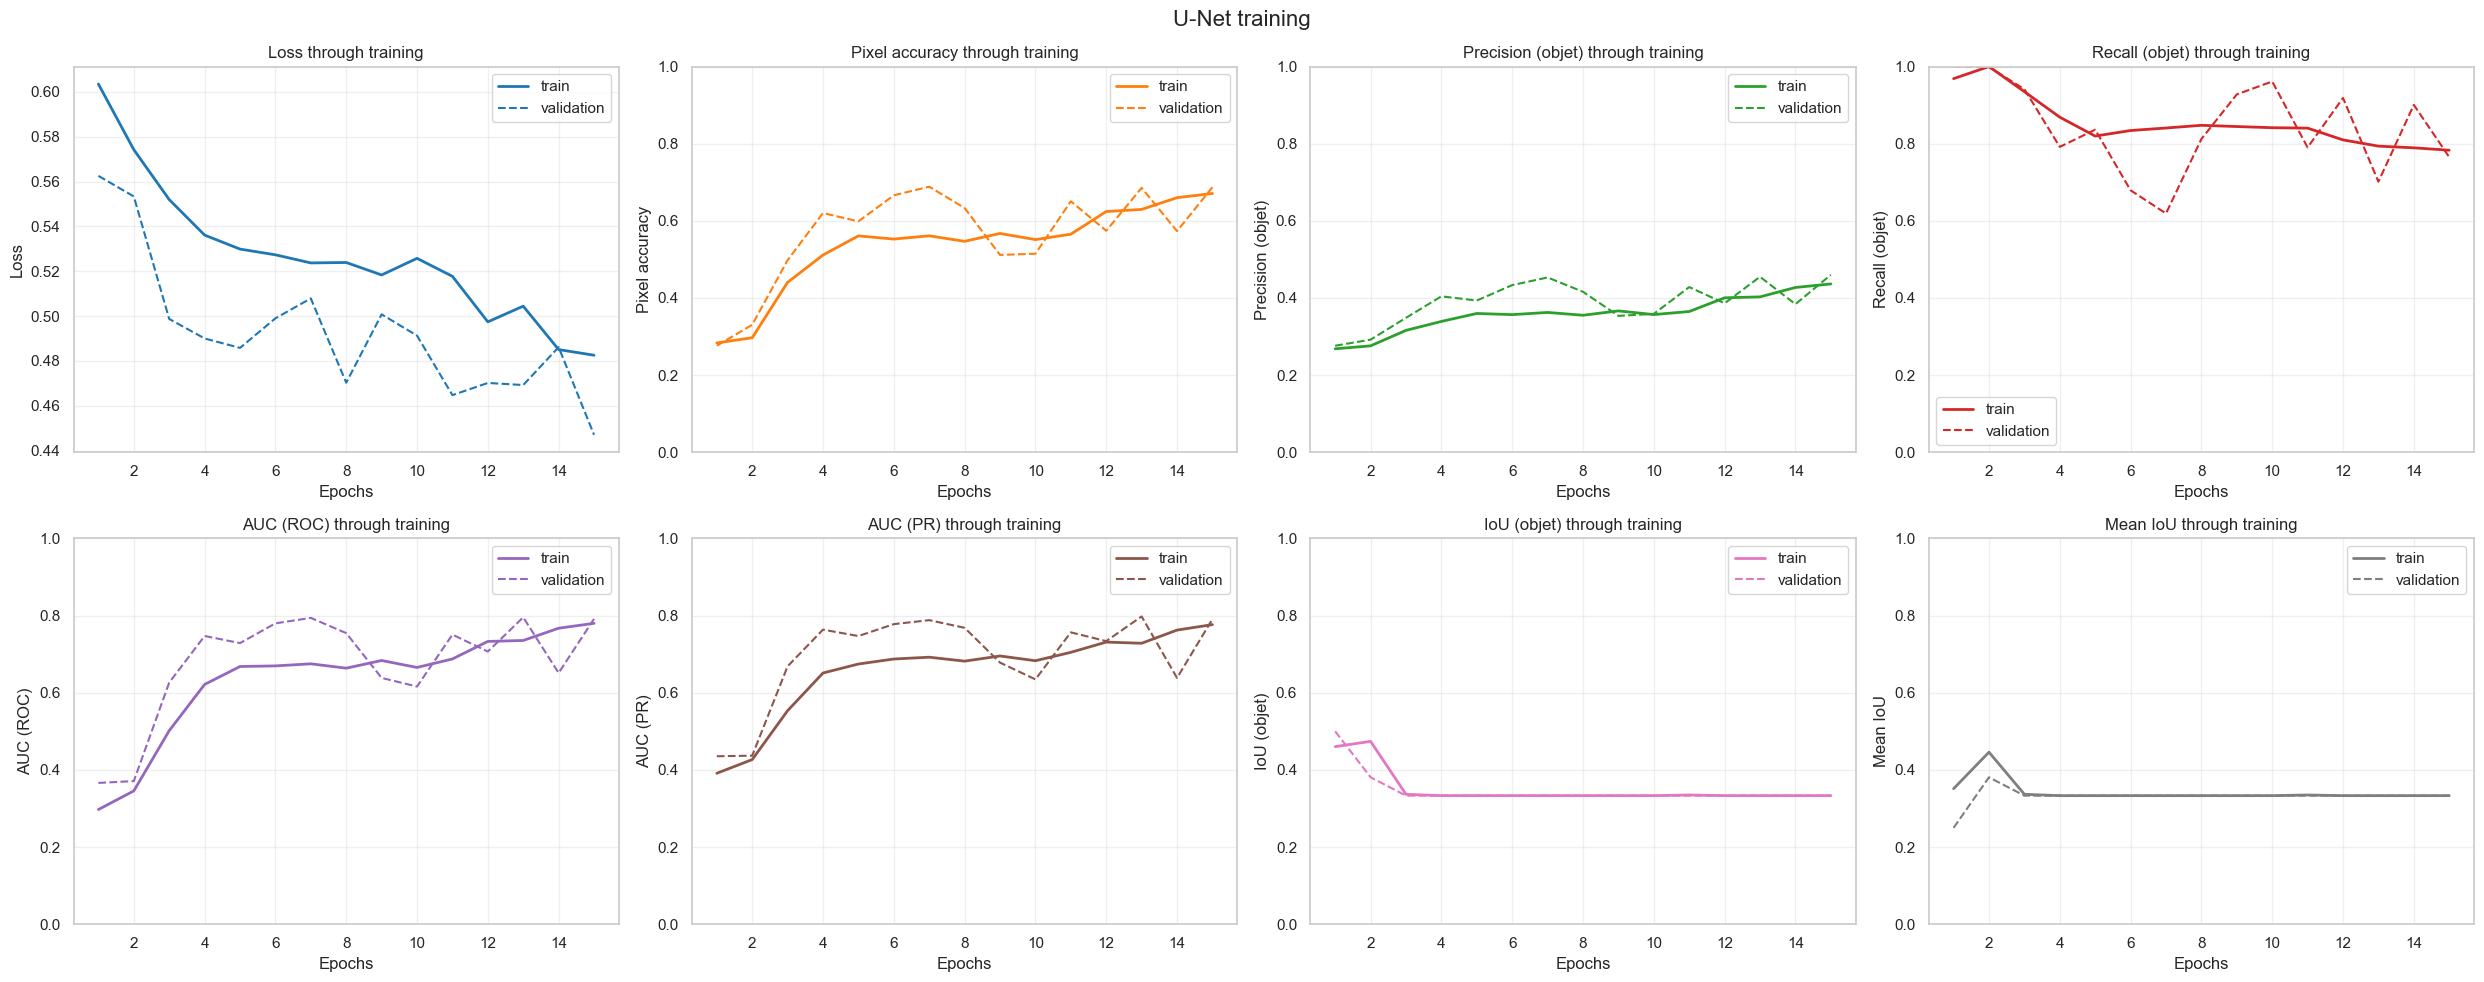

In [12]:
historic = pd.DataFrame(history.history)
epochs = range(1, len(historic) + 1)  # robuste si early stopping

metrics = [
    "loss", "accuracy", "precision", "recall",
    "auc", "auc_pr", "iou_fg", "mean_iou",
]
titles = {
    "loss": "Loss",
    "accuracy": "Pixel accuracy",
    "precision": "Precision (objet)",
    "recall": "Recall (objet)",
    "auc": "AUC (ROC)",
    "auc_pr": "AUC (PR)",
    "iou_fg": "IoU (objet)",
    "mean_iou": "Mean IoU",
}

figure, axes = plt.subplots(2, 4, figsize=(25, 10))
palette = sns.color_palette("tab10", n_colors=len(metrics))

for index, (metric_name, axis) in enumerate(zip(metrics, axes.flat)):
    if metric_name not in historic.columns:
        axis.set_visible(False)  # métrique absente de l'historique
        continue

    color = palette[index]
    axis.plot(epochs, historic[metric_name], lw=2, color=color, label="train")
    if "val_" + metric_name in historic.columns:
        axis.plot(epochs, historic["val_" + metric_name], ls="--", color=color, label="validation")

    if metric_name != "loss":
        axis.set_ylim(0, 1)
    axis.set_ylabel(titles[metric_name])
    axis.set_xlabel("Epochs")
    axis.set_title("%s through training" % titles[metric_name])
    axis.grid(alpha=0.3)
    axis.legend()

plt.suptitle("U-Net training", fontsize=16)
plt.tight_layout()
plt.show()

In [13]:
display(historic)

,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou
0,0.603476,0.283553,0.268236,0.968505,0.297356,0.391335,0.460432,0.351428,0.562542,0.276226,0.276226,1.000000,0.366325,0.435502,0.500000,0.250000
1,0.574215,0.296904,0.275942,0.999914,0.345636,0.426821,0.474074,0.446053,0.553352,0.330663,0.291975,0.998734,0.371090,0.436912,0.380952,0.380952
2,0.551966,0.440481,0.316061,0.934761,0.501832,0.553604,0.336842,0.336842,0.498740,0.497917,0.348568,0.941047,0.626414,0.668624,0.333333,0.333333
3,0.536128,0.511367,0.339207,0.868607,0.621576,0.651218,0.333333,0.333333,0.490051,0.620228,0.404280,0.791626,0.747222,0.763668,0.333333,0.333333
4,0.529894,0.560924,0.359839,0.819675,0.668132,0.674570,0.333333,0.333333,0.485841,0.598563,0.393383,0.836254,0.728724,0.747032,0.333333,0.333333
5,0.527341,0.552733,0.356861,0.834086,0.669647,0.687506,0.333333,0.333333,0.499026,0.666101,0.433377,0.679081,0.779938,0.777922,0.333333,0.333333
6,0.523725,0.561136,0.362489,0.840579,0.675062,0.692182,0.333333,0.333333,0.507900,0.688434,0.453170,0.619035,0.794130,0.788219,0.333333,0.333333
7,0.523913,0.546881,0.355216,0.847596,0.663776,0.681972,0.333333,0.333333,0.470311,0.633218,0.416027,0.812098,0.754669,0.768378,0.333333,0.333333
8,0.518356,0.567237,0.366526,0.844392,0.683672,0.695396,0.333333,0.333333,0.500809,0.511601,0.353613,0.927731,0.638453,0.678215,0.333333,0.333333
9,0.525773,0.551349,0.356962,0.841352,0.665640,0.683061,0.333333,0.333333,0.491306,0.514686,0.358741,0.961168,0.616242,0.634705,0.333333,0.333333


In [14]:
y_test_one_hot = tf.one_hot(y_test, depth=2)
score = model.evaluate(X_test, y_test_one_hot, batch_size=batches_size, return_dict=True)

# Dice (= F1 pixel) déduit de la précision et du recall de la classe objet
dice = 2 * score["precision"] * score["recall"] / (score["precision"] + score["recall"] + 1e-8)

df_score = pd.DataFrame(
    {
        "Métrique": [
            "Loss",
            "Accuracy",
            "Precision (objet)",
            "Recall (objet)",
            "Dice / F1 (objet)",
            "IoU (objet)",
            "Mean IoU",
            "AUC (ROC)",
            "AUC (PR)",
        ],
        "Valeur": [
            score["loss"],
            score["accuracy"],
            score["precision"],
            score["recall"],
            dice,
            score["iou_fg"],
            score["mean_iou"],
            score["auc"],
            score["auc_pr"],
        ],
    }
).set_index("Métrique")

display(df_score.style.format("{:.4f}"))

20/20 [==============================] - 3s 146ms/step - loss: 0.4365 - accuracy: 0.7068 - precision: 0.5022 - recall: 0.7597 - auc: 0.7989 - auc_pr: 0.7907 - iou_fg: 0.3333 - mean_iou: 0.3333


,Valeur
Métrique,
Loss,0.4365
Accuracy,0.7068
Precision (objet),0.5022
Recall (objet),0.7597
Dice / F1 (objet),0.6047
IoU (objet),0.3333
Mean IoU,0.3333
AUC (ROC),0.7989
AUC (PR),0.7907


## UNet simplifier

&nbsp;&nbsp;&nbsp;&nbsp; Le réseau U-Net simplifié est un réseau de neurones convolutif qui repose grandement sur le U-Net mais dans lequel nous avons essayer de réduire le nombre de neurones en passant de 31 millions à un peu moins de 8 millions.

&nbsp;&nbsp;&nbsp;&nbsp; L'encodeur est composé de trois blocs successifs contenant chacun deux couches de convolution de taille 3 × 3, avec une activation SiLU. Chaque bloc est suivi d'une normalisation par lot (Batch Normalization) et d'une couche de Dropout de taux 0,2. Entre les blocs, une opération de max pooling de taille 2 × 2 réduit de moitié la résolution spatiale. Le nombre de filtres augmente progressivement : 64, 128 puis 256.

&nbsp;&nbsp;&nbsp;&nbsp; Le bottleneck, situé entre l'encodeur et le décodeur, constitue le niveau le plus profond du réseau. Il reprend la même structure de convolution avec 512 filtres et permet d'extraire des caractéristiques plus abstraites de l'image.

&nbsp;&nbsp;&nbsp;&nbsp; Le décodeur est composé de trois blocs. À chaque étape, une convolution transposée de taille 2 × 2 augmente la résolution spatiale. Les caractéristiques obtenues sont ensuite concaténées avec celles issues du bloc correspondant de l'encodeur, après un recadrage (cropping) permettant d'adapter leurs dimensions. Ces connexions de saut permettent de récupérer les informations spatiales perdues lors de la réduction de résolution et d'améliorer la précision de la segmentation.

&nbsp;&nbsp;&nbsp;&nbsp; Enfin, une convolution de taille 1 × 1 avec une activation Softmax permet de produire une carte de segmentation en deux classes. Un recadrage final ajuste les dimensions de la sortie à 388 × 388 pixels.

&nbsp;&nbsp;&nbsp;&nbsp; Par rapport à un U-Net classique, notre architecture est simplifiée puisqu'elle comporte trois niveaux d'encodage et trois niveaux de décodage, au lieu des quatre niveaux. Elle conserve néanmoins le principe fondamental du U-Net, à savoir les connexions de saut entre l'encodeur et le décodeur. Elle se distingue également par l'utilisation de la fonction d'activation SiLU et de couches de Dropout avec un taux de 0,2 afin de limiter le surapprentissage.

In [15]:
def conv_block(x, filters):
    x = keras.layers.Conv2D(
        filters, 3, activation="silu", padding="valid"
    )(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Conv2D(
        filters, 3, activation="silu", padding="valid"
    )(x)

    return x


def up_block(x, skip, filters, crop):
    x = keras.layers.Conv2DTranspose(
        filters, 2, strides=2, padding="valid"
    )(x)

    skip = keras.layers.Cropping2D(
        cropping=((crop, crop), (crop, crop))
    )(skip)

    x = keras.layers.Concatenate()([skip, x])

    return conv_block(x, filters)


def get_model_2(input_shape=(572, 572, 1), num_classes=2):

    inputs = keras.Input(shape=input_shape)  # 572 x 572 x 1

    # Encodeur
    x1 = conv_block(inputs, 64)  # 568 x 568
    x2 = conv_block(
        keras.layers.MaxPooling2D(2)(x1), 128
    )  # 280 x 280

    x3 = conv_block(
        keras.layers.MaxPooling2D(2)(x2), 256
    )  # 136 x 136

    # Bottleneck
    b = conv_block(
        keras.layers.MaxPooling2D(2)(x3), 512
    )  # 64 x 64

    # Décodeur
    d3 = up_block(b, x3, 256, crop=4)    # 124 x 124
    d2 = up_block(d3, x2, 128, crop=16)  # 244 x 244
    d1 = up_block(d2, x1, 64, crop=40)   # 484 x 484

    # Recadrage final : 484 -> 388
    d1 = keras.layers.Cropping2D(
        cropping=((48, 48), (48, 48))
    )(d1)  # 388 x 388

    # Couche de segmentation : 2 classes
    outputs = keras.layers.Conv2D(
        num_classes, 1, activation="softmax", padding="valid"
    )(d1)  # 388 x 388 x 2

    model = keras.Model(
        inputs, outputs, name="unet"
    )

    return model


model_2 = get_model_2()
model_2.summary()


Model: "unet"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_3 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_38 (Conv2D)             (None, 570, 570, 64  640         ['input_3[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 570, 570, 64  256        ['conv2d_38[0][0]']              
 alization)                     )                                                              

In [16]:
callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

n_epochs = 15
batches_size = 5

y_train_one_hot_2 = tf.one_hot(y_train, depth=2)
y_val_one_hot_2 = tf.one_hot(y_val, depth=2)

opt_2 = tf.keras.optimizers.Adam(learning_rate=1e-4)

model_2.compile(
    optimizer=opt_2,
    loss=combined_loss,
    metrics=[
        keras.metrics.CategoricalAccuracy(name="accuracy"),
        keras.metrics.Precision(class_id=1, name="precision"),
        keras.metrics.Recall(class_id=1, name="recall"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.AUC(curve="PR", name="auc_pr"),
        keras.metrics.OneHotIoU(num_classes=2, target_class_ids=[1], name="iou_fg"),
        keras.metrics.OneHotMeanIoU(num_classes=2, name="mean_iou"),
    ],
)

history_2 = model_2.fit(
    X_train,
    y_train_one_hot_2,
    epochs=n_epochs,
    batch_size=batches_size,
    validation_data=(X_val, y_val_one_hot_2),
    callbacks=[callback],
)

Epoch 1/15
64/64 [==============================] - 129s 2s/step - loss: 0.5279 - accuracy: 0.5886 - precision: 0.3742 - recall: 0.7957 - auc: 0.6620 - auc_pr: 0.6720 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.6035 - val_accuracy: 0.2762 - val_precision: 0.2762 - val_recall: 1.0000 - val_auc: 0.3629 - val_auc_pr: 0.4330 - val_iou_fg: 0.5000 - val_mean_iou: 0.2500
Epoch 2/15
64/64 [==============================] - 129s 2s/step - loss: 0.5131 - accuracy: 0.6166 - precision: 0.3923 - recall: 0.7841 - auc: 0.7042 - auc_pr: 0.7145 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.7145 - val_accuracy: 0.7238 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.8035 - val_auc_pr: 0.8033 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500
Epoch 3/15
64/64 [==============================] - 129s 2s/step - loss: 0.4961 - accuracy: 0.6449 - precision: 0.4157 - recall: 0.8014 - auc: 0.7476 - auc_pr: 0.7534 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.8544 - val_accuracy: 0.72

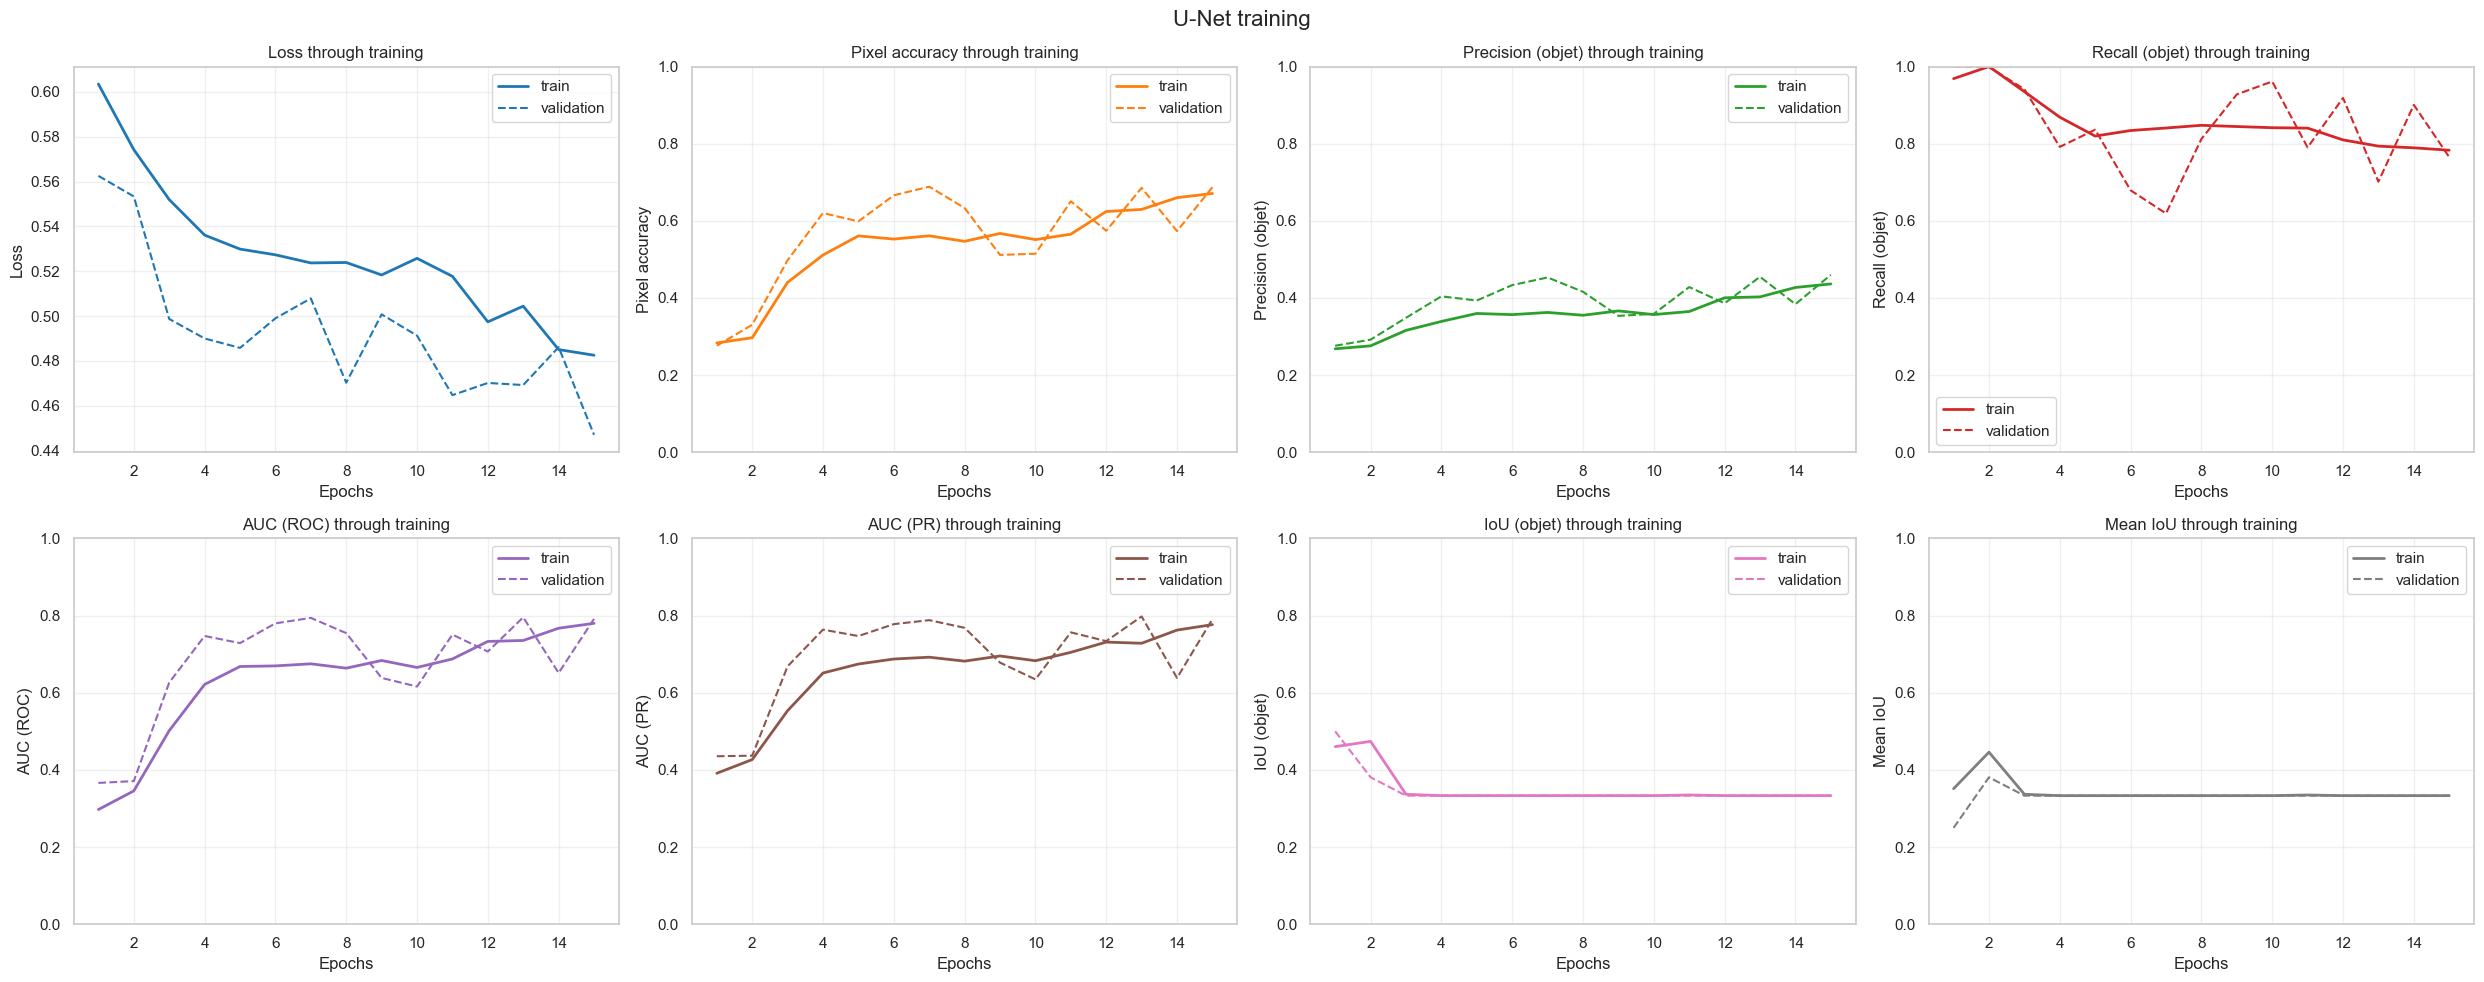

In [17]:
historic_2 = pd.DataFrame(history.history)
epochs = range(1, len(historic_2) + 1)  # robuste si early stopping

metrics = [
    "loss", "accuracy", "precision", "recall",
    "auc", "auc_pr", "iou_fg", "mean_iou",
]
titles = {
    "loss": "Loss",
    "accuracy": "Pixel accuracy",
    "precision": "Precision (objet)",
    "recall": "Recall (objet)",
    "auc": "AUC (ROC)",
    "auc_pr": "AUC (PR)",
    "iou_fg": "IoU (objet)",
    "mean_iou": "Mean IoU",
}

figure, axes = plt.subplots(2, 4, figsize=(25, 10))
palette = sns.color_palette("tab10", n_colors=len(metrics))

for index, (metric_name, axis) in enumerate(zip(metrics, axes.flat)):
    if metric_name not in historic_2.columns:
        axis.set_visible(False)  # métrique absente de l'historique
        continue

    color = palette[index]
    axis.plot(epochs, historic_2[metric_name], lw=2, color=color, label="train")
    if "val_" + metric_name in historic_2.columns:
        axis.plot(epochs, historic_2["val_" + metric_name], ls="--", color=color, label="validation")

    if metric_name != "loss":
        axis.set_ylim(0, 1)
    axis.set_ylabel(titles[metric_name])
    axis.set_xlabel("Epochs")
    axis.set_title("%s through training" % titles[metric_name])
    axis.grid(alpha=0.3)
    axis.legend()

plt.suptitle("U-Net training", fontsize=16)
plt.tight_layout()
plt.show()

In [18]:
display(historic_2)

,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou
0,0.603476,0.283553,0.268236,0.968505,0.297356,0.391335,0.460432,0.351428,0.562542,0.276226,0.276226,1.000000,0.366325,0.435502,0.500000,0.250000
1,0.574215,0.296904,0.275942,0.999914,0.345636,0.426821,0.474074,0.446053,0.553352,0.330663,0.291975,0.998734,0.371090,0.436912,0.380952,0.380952
2,0.551966,0.440481,0.316061,0.934761,0.501832,0.553604,0.336842,0.336842,0.498740,0.497917,0.348568,0.941047,0.626414,0.668624,0.333333,0.333333
3,0.536128,0.511367,0.339207,0.868607,0.621576,0.651218,0.333333,0.333333,0.490051,0.620228,0.404280,0.791626,0.747222,0.763668,0.333333,0.333333
4,0.529894,0.560924,0.359839,0.819675,0.668132,0.674570,0.333333,0.333333,0.485841,0.598563,0.393383,0.836254,0.728724,0.747032,0.333333,0.333333
5,0.527341,0.552733,0.356861,0.834086,0.669647,0.687506,0.333333,0.333333,0.499026,0.666101,0.433377,0.679081,0.779938,0.777922,0.333333,0.333333
6,0.523725,0.561136,0.362489,0.840579,0.675062,0.692182,0.333333,0.333333,0.507900,0.688434,0.453170,0.619035,0.794130,0.788219,0.333333,0.333333
7,0.523913,0.546881,0.355216,0.847596,0.663776,0.681972,0.333333,0.333333,0.470311,0.633218,0.416027,0.812098,0.754669,0.768378,0.333333,0.333333
8,0.518356,0.567237,0.366526,0.844392,0.683672,0.695396,0.333333,0.333333,0.500809,0.511601,0.353613,0.927731,0.638453,0.678215,0.333333,0.333333
9,0.525773,0.551349,0.356962,0.841352,0.665640,0.683061,0.333333,0.333333,0.491306,0.514686,0.358741,0.961168,0.616242,0.634705,0.333333,0.333333


In [19]:
y_test_one_hot_2 = tf.one_hot(y_test, depth=2)
score_2 = model_2.evaluate(X_test, y_test_one_hot_2, batch_size=batches_size, return_dict=True)

# Dice (= F1 pixel) déduit de la précision et du recall de la classe objet
dice_2 = 2 * score_2["precision"] * score_2["recall"] / (score_2["precision"] + score_2["recall"] + 1e-8)

df_score_2 = pd.DataFrame(
    {
        "Métrique": [
            "Loss",
            "Accuracy",
            "Precision (objet)",
            "Recall (objet)",
            "Dice / F1 (objet)",
            "IoU (objet)",
            "Mean IoU",
            "AUC (ROC)",
            "AUC (PR)",
        ],
        "Valeur": [
            score_2["loss"],
            score_2["accuracy"],
            score_2["precision"],
            score_2["recall"],
            dice_2,
            score_2["iou_fg"],
            score_2["mean_iou"],
            score_2["auc"],
            score_2["auc_pr"],
        ],
    }
).set_index("Métrique")

display(df_score_2.style.format("{:.4f}"))

20/20 [==============================] - 5s 219ms/step - loss: 0.4713 - accuracy: 0.7560 - precision: 0.5929 - recall: 0.5532 - auc: 0.8286 - auc_pr: 0.8057 - iou_fg: 0.3333 - mean_iou: 0.3333


,Valeur
Métrique,
Loss,0.4713
Accuracy,0.7560
Precision (objet),0.5929
Recall (objet),0.5532
Dice / F1 (objet),0.5724
IoU (objet),0.3333
Mean IoU,0.3333
AUC (ROC),0.8286
AUC (PR),0.8057


In [20]:
def add_dice(s):
    return 2 * s["precision"] * s["recall"] / (s["precision"] + s["recall"] + 1e-8)

scores = {"U-Net": score, "U-Net Simplifié": score_2}

compare = pd.DataFrame({
    "Model": list(scores.keys()),
    "Loss": [s["loss"] for s in scores.values()],
    "Accuracy": [s["accuracy"] for s in scores.values()],
    "Precision": [s["precision"] for s in scores.values()],
    "Recall": [s["recall"] for s in scores.values()],
    "Dice / F1": [add_dice(s) for s in scores.values()],
    "IoU (objet)": [s["iou_fg"] for s in scores.values()],
    "Mean IoU": [s["mean_iou"] for s in scores.values()],
    "AUC (ROC)": [s["auc"] for s in scores.values()],
    "AUC (PR)": [s["auc_pr"] for s in scores.values()],
}).set_index("Model")

display(
    compare.style
    .format("{:.4f}")
    .highlight_min(subset=["Loss"], color="grey")
    .highlight_max(subset=compare.columns.drop("Loss"), color="grey")
)

,Loss,Accuracy,Precision,Recall,Dice / F1,IoU (objet),Mean IoU,AUC (ROC),AUC (PR)
Model,,,,,,,,,
U-Net,0.4365,0.7068,0.5022,0.7597,0.6047,0.3333,0.3333,0.7989,0.7907
U-Net Simplifié,0.4713,0.7560,0.5929,0.5532,0.5724,0.3333,0.3333,0.8286,0.8057


# ResNet

## ResNet-50

&nbsp;&nbsp;&nbsp;&nbsp; Le réseau ResNet50_Segmentation est un réseau de neurones convolutif destiné à la segmentation d'images. Il s'inspire de l'architecture ResNet-50 et repose sur des blocs résiduels (bottleneck blocks), qui permettent de faciliter l'apprentissage des réseaux profonds grâce à des connexions de raccourci (shortcut connections).

&nbsp;&nbsp;&nbsp;&nbsp; Le réseau commence par une convolution de taille 7 × 7 avec 64 filtres et un pas de 2, suivie d'une opération de max pooling de taille 3 × 3. Cette première étape permet de réduire la résolution spatiale de l'image tout en extrayant les premières caractéristiques.

&nbsp;&nbsp;&nbsp;&nbsp; L'extraction des caractéristiques repose ensuite sur quatre groupes de blocs résiduels contenant respectivement 3, 4, 6 et 3 blocs. Chaque bloc est composé de trois convolutions successives de tailles 1 × 1, 3 × 3 et 1 × 1. Des couches de Batch Normalization et de Dropout (0,2) sont intégrées après les convolutions afin de stabiliser l'apprentissage et de limiter le surapprentissage. Les connexions résiduelles permettent quant à elles de transmettre directement les informations d'entrée vers la sortie de chaque bloc.

&nbsp;&nbsp;&nbsp;&nbsp; Contrairement à la ResNet-50 originale, qui se termine par une couche de classification, notre architecture intègre une tête de segmentation. Celle-ci est composée d'une convolution 3 × 3 avec 256 filtres, suivie d'une convolution transposée (Conv2DTranspose) de taille 4 × 4 avec 128 filtres et un pas de 4, permettant d'augmenter la résolution spatiale. Enfin, une convolution 1 × 1 avec une activation Softmax produit une carte de segmentation en deux classes, redimensionnée à 388 × 388 pixels.

&nbsp;&nbsp;&nbsp;&nbsp; La principale différence entre ResNet-50 et notre architecture réside donc dans leur objectif final. ResNet-50 est initialement conçue pour la classification d'images et utilise une couche de pooling global suivie d'une couche dense pour prédire une classe. Notre modèle conserve la structure résiduelle de ResNet-50, mais remplace cette partie de classification par un décodeur simplifié permettant d'effectuer une segmentation pixel par pixel. De plus, nous avons ajouté des couches de Dropout avec un taux de 0,2 dans les blocs résiduels afin de limiter le surapprentissage.

In [21]:
def bottleneck_block(x, filters, stride=1):
    shortcut = x

    x = keras.layers.Conv2D(filters, 1, strides=stride, padding="same", use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Activation("relu")(x)

    x = keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Activation("relu")(x)

    x = keras.layers.Conv2D(filters * 4, 1, padding="same", use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.2)(x)

    if stride != 1 or shortcut.shape[-1] != filters * 4:
        shortcut = keras.layers.Conv2D(filters * 4, 1, strides=stride,
                                        padding="same", use_bias=False)(shortcut)
        shortcut = keras.layers.BatchNormalization()(shortcut)

    x = keras.layers.Add()([x, shortcut])
    return keras.layers.Activation("relu")(x)


def get_resnet(input_shape=(572, 572, 1), num_classes=2):
    inputs = keras.layers.Input(shape=input_shape)

    # Encodeur ResNet-50 avec sauvegarde des activations intermédiaires pour les skips
    # Niveau 1 (Input resolution / 2)
    x1 = keras.layers.Conv2D(64, 7, strides=2, padding="same", use_bias=False)(inputs)
    x1 = keras.layers.BatchNormalization()(x1)
    x1 = keras.layers.Activation("relu")(x1) # 286x286

    # Niveau 2 (Input resolution / 4)
    x2 = keras.layers.MaxPooling2D(3, strides=2, padding="same")(x1) # 143x143
    x2 = bottleneck_block(x2, 64)
    x2 = bottleneck_block(x2, 64)
    x2 = bottleneck_block(x2, 64)

    # Niveau 3 (Input resolution / 8)
    x3 = bottleneck_block(x2, 128, stride=2) # 72x72
    x3 = bottleneck_block(x3, 128)
    x3 = bottleneck_block(x3, 128)
    x3 = bottleneck_block(x3, 128)

    # Niveau 4 (Input resolution / 16)
    x4 = bottleneck_block(x3, 256, stride=2) # 36x36
    x4 = bottleneck_block(x4, 256)
    x4 = bottleneck_block(x4, 256)
    x4 = bottleneck_block(x4, 256)
    x4 = bottleneck_block(x4, 256)
    x4 = bottleneck_block(x4, 256)

    # Bottleneck le plus profond (Input resolution / 32)
    b = bottleneck_block(x4, 512, stride=2) # 18x18
    b = bottleneck_block(b, 512)
    b = bottleneck_block(b, 512)

    # DECODEUR PROGRESSIF avec connexions de saut (Skip Connections)
    # Étape 1 : 18x18 -> 36x36
    u1 = keras.layers.Conv2DTranspose(256, 2, strides=2, padding="same")(b)
    u1 = keras.layers.Concatenate()([u1, x4])
    u1 = keras.layers.Conv2D(256, 3, padding="same", activation="relu")(u1)

    # Étape 2 : 36x36 -> 72x72
    u2 = keras.layers.Conv2DTranspose(128, 2, strides=2, padding="same")(u1)
    u2 = keras.layers.Concatenate()([u2, x3])
    u2 = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(u2)

    # Étape 3 : 72x72 -> 143x143 -> Resizing à 143x143 si nécessaire
    u3 = keras.layers.Conv2DTranspose(64, 2, strides=2, padding="same")(u2)
    u3 = keras.layers.Resizing(143, 143)(u3)
    u3 = keras.layers.Concatenate()([u3, x2])
    u3 = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(u3)

    # Étape 4 : Redimensionnement final vers la sortie cible 388x388
    u4 = keras.layers.Conv2DTranspose(32, 2, strides=2, padding="same")(u3)
    u4 = keras.layers.Resizing(388, 388)(u4)

    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(u4)

    model_resnet = keras.Model(inputs, outputs, name="ResNet")
    return model_resnet

model_resnet = get_resnet()
model_resnet.summary()

Model: "ResNet"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_4 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_53 (Conv2D)             (None, 286, 286, 64  3136        ['input_4[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization_7 (BatchNo  (None, 286, 286, 64  256        ['conv2d_53[0][0]']              
 rmalization)                   )                                                            

In [22]:
callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

n_epochs = 15
batches_size = 5

y_train_one_hot_resnet = tf.one_hot(y_train, depth=2)
y_val_one_hot_resnet = tf.one_hot(y_val, depth=2)

opt_resnet = tf.keras.optimizers.Adam(learning_rate=1e-4)

model_resnet.compile(
    optimizer=opt_resnet,
    loss=combined_loss,
    metrics=[
            keras.metrics.CategoricalAccuracy(name="accuracy"),
            keras.metrics.Precision(class_id=1, name="precision"),
            keras.metrics.Recall(class_id=1, name="recall"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.AUC(curve="PR", name="auc_pr"),
            keras.metrics.OneHotIoU(num_classes=2, target_class_ids=[1], name="iou_fg"),
            keras.metrics.OneHotMeanIoU(num_classes=2, name="mean_iou"),
    ],
)

history_resnet = model_resnet.fit(
    X_train,
    y_train_one_hot_resnet,
    epochs=n_epochs,
    batch_size=batches_size,
    validation_data=(X_val, y_val_one_hot_resnet),
    callbacks=[callback],
)

Epoch 1/15
64/64 [==============================] - 27s 348ms/step - loss: 0.5685 - accuracy: 0.4976 - precision: 0.3189 - recall: 0.7700 - auc: 0.5266 - auc_pr: 0.5367 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.5988 - val_accuracy: 0.2762 - val_precision: 0.2762 - val_recall: 1.0000 - val_auc: 0.3266 - val_auc_pr: 0.4066 - val_iou_fg: 0.4571 - val_mean_iou: 0.4571
Epoch 2/15
64/64 [==============================] - 21s 322ms/step - loss: 0.5522 - accuracy: 0.5881 - precision: 0.3593 - recall: 0.6855 - auc: 0.6355 - auc_pr: 0.6318 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.5809 - val_accuracy: 0.2879 - val_precision: 0.2788 - val_recall: 0.9942 - val_auc: 0.3425 - val_auc_pr: 0.4196 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333
Epoch 3/15
64/64 [==============================] - 20s 321ms/step - loss: 0.5391 - accuracy: 0.6254 - precision: 0.3876 - recall: 0.6864 - auc: 0.6753 - auc_pr: 0.6638 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.6561 - val_accuracy: 0.6781 - v

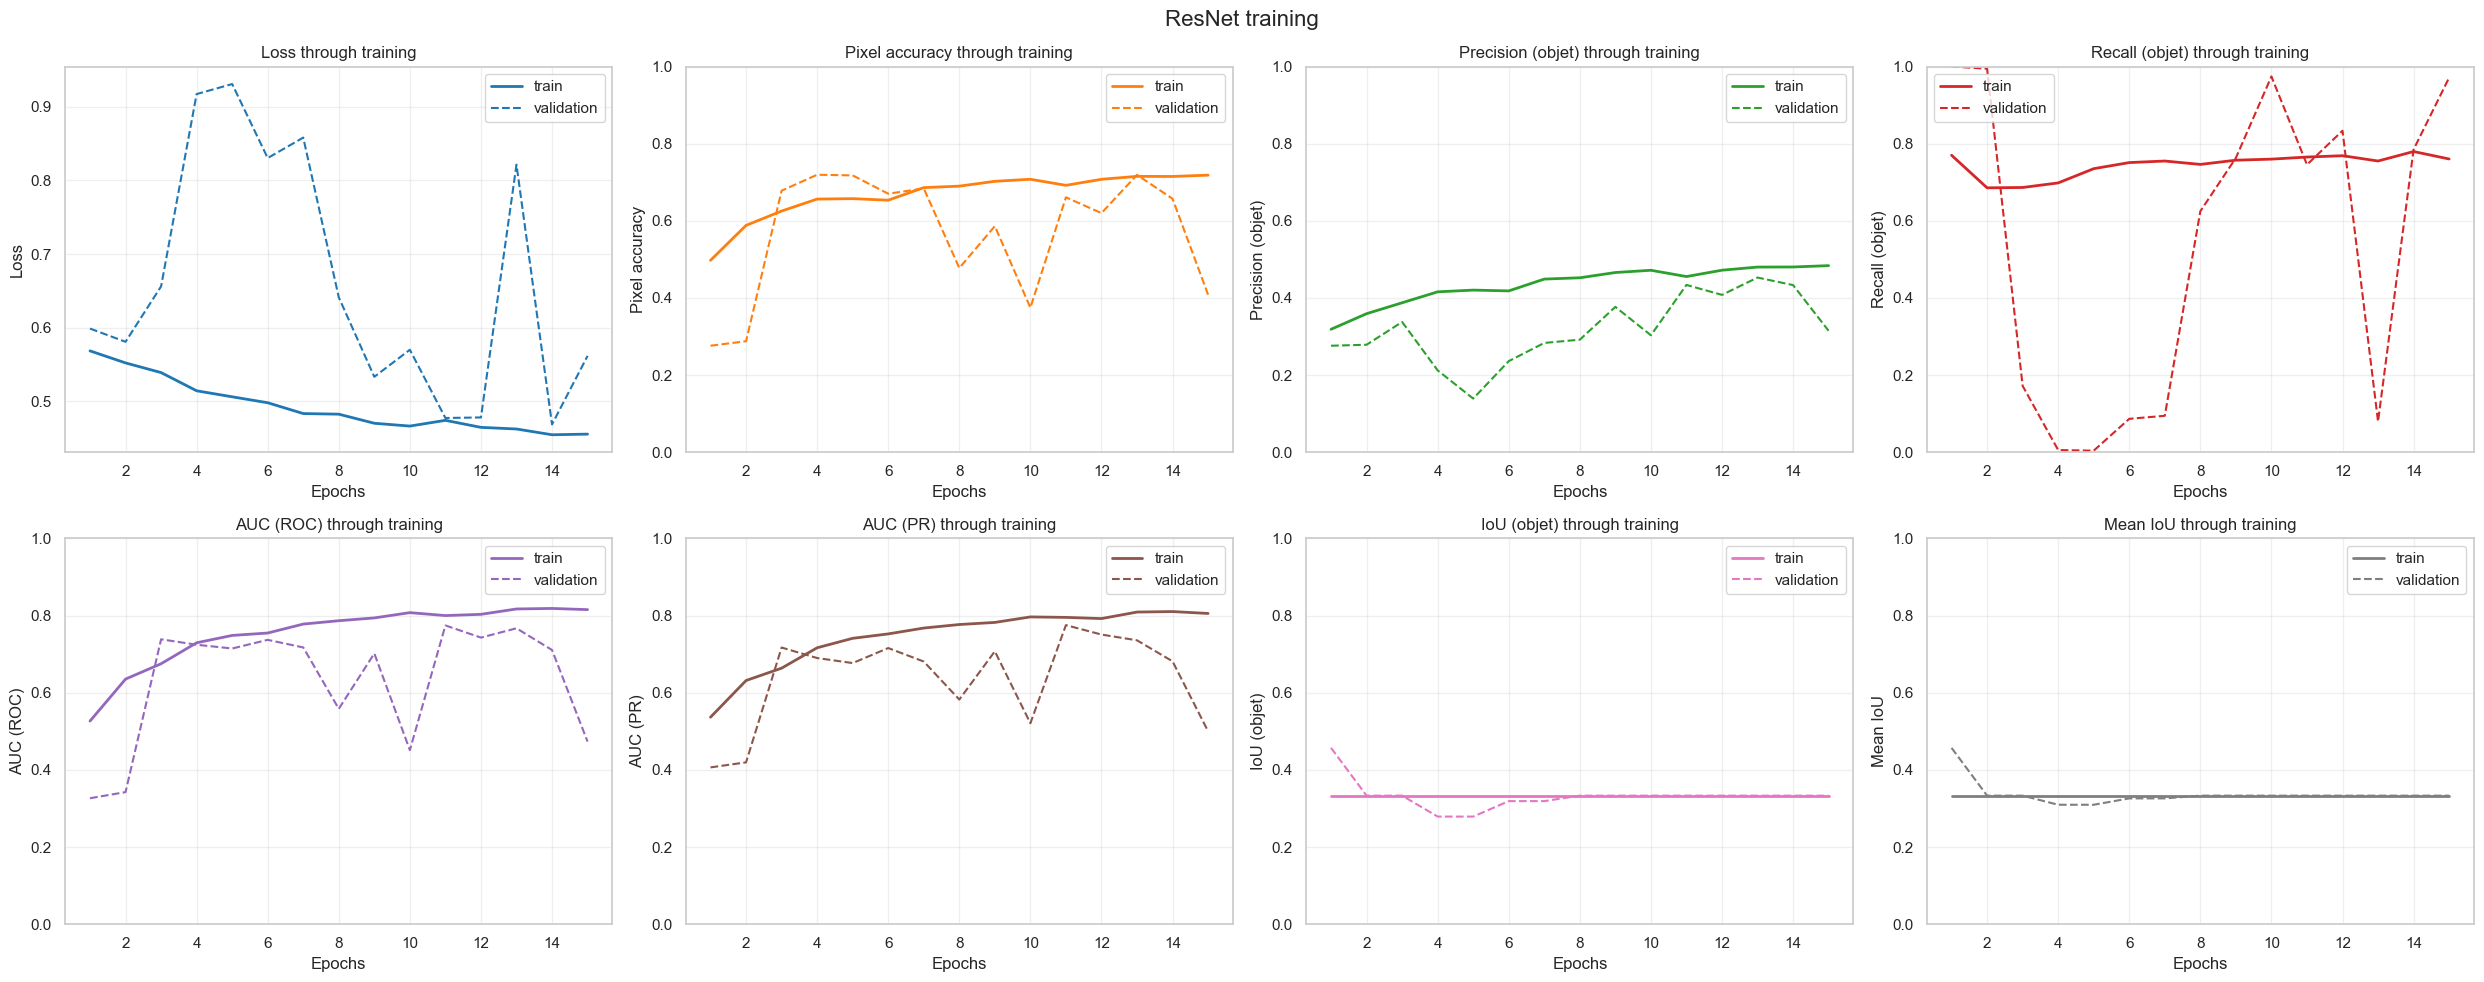

In [23]:
historic_resnet = pd.DataFrame(history_resnet.history)
epochs = range(1, len(historic_resnet) + 1)

metrics = [
    "loss", "accuracy", "precision", "recall",
    "auc", "auc_pr", "iou_fg", "mean_iou",
]
titles = {
    "loss": "Loss",
    "accuracy": "Pixel accuracy",
    "precision": "Precision (objet)",
    "recall": "Recall (objet)",
    "auc": "AUC (ROC)",
    "auc_pr": "AUC (PR)",
    "iou_fg": "IoU (objet)",
    "mean_iou": "Mean IoU",
}

figure, axes = plt.subplots(2, 4, figsize=(25, 10))
palette = sns.color_palette("tab10", n_colors=len(metrics))

for index, (metric_name, axis) in enumerate(zip(metrics, axes.flat)):
    if metric_name not in historic_resnet.columns:
        axis.set_visible(False)  # métrique absente de l'historique
        continue

    color = palette[index]
    axis.plot(epochs, historic_resnet[metric_name], lw=2, color=color, label="train")
    if "val_" + metric_name in historic_resnet.columns:
        axis.plot(epochs, historic_resnet["val_" + metric_name], ls="--", color=color, label="validation")

    if metric_name != "loss":
        axis.set_ylim(0, 1)
    axis.set_ylabel(titles[metric_name])
    axis.set_xlabel("Epochs")
    axis.set_title("%s through training" % titles[metric_name])
    axis.grid(alpha=0.3)
    axis.legend()

plt.suptitle("ResNet training", fontsize=16)
plt.tight_layout()
plt.show()

In [24]:
display(historic_resnet)

,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou
0,0.568526,0.497606,0.318858,0.769973,0.526646,0.536740,0.333333,0.333333,0.598803,0.276238,0.276229,0.999998,0.326648,0.406593,0.457143,0.457143
1,0.552186,0.588135,0.359278,0.685507,0.635491,0.631762,0.333333,0.333333,0.580854,0.287934,0.278785,0.994229,0.342529,0.419642,0.333333,0.333333
2,0.539059,0.625359,0.387602,0.686397,0.675254,0.663800,0.333333,0.333333,0.656084,0.678127,0.337842,0.172145,0.738566,0.717260,0.333333,0.333333
3,0.514328,0.656387,0.415925,0.698265,0.729595,0.716658,0.333333,0.333333,0.917224,0.719445,0.212333,0.005784,0.724519,0.690012,0.279070,0.309748
4,0.506164,0.657456,0.420421,0.735153,0.748622,0.741142,0.333333,0.333333,0.930839,0.717726,0.139272,0.004227,0.714753,0.676981,0.279070,0.309748
5,0.498108,0.653462,0.418333,0.750979,0.754874,0.752567,0.333333,0.333333,0.830350,0.670281,0.236285,0.086757,0.737148,0.715896,0.319149,0.326241
6,0.483417,0.686045,0.448972,0.754997,0.778083,0.767768,0.333333,0.333333,0.858115,0.683847,0.283492,0.094634,0.717546,0.680972,0.319149,0.326241
7,0.482580,0.689919,0.452366,0.746246,0.786775,0.776915,0.333333,0.333333,0.641230,0.477711,0.291924,0.624885,0.558427,0.582421,0.333333,0.333333
8,0.470235,0.702424,0.465999,0.757183,0.794023,0.782348,0.333333,0.333333,0.533309,0.586152,0.376937,0.763017,0.701941,0.707469,0.333333,0.333333
9,0.466421,0.707720,0.471832,0.759899,0.807720,0.796618,0.333333,0.333333,0.570039,0.374815,0.303325,0.974181,0.451351,0.521058,0.333333,0.333333


In [25]:
y_test_one_hot_resnet = tf.one_hot(y_test, depth=2)
score_resnet = model_resnet.evaluate(X_test, y_test_one_hot_resnet, batch_size=batches_size, return_dict=True)

# Dice (= F1 pixel) déduit de la précision et du recall de la classe objet
dice_resnet = 2 * score_resnet["precision"] * score_resnet["recall"] / (score_resnet["precision"] + score_resnet["recall"] + 1e-8)

df_score_resnet = pd.DataFrame(
    {
        "Métrique": [
            "Loss",
            "Accuracy",
            "Precision (objet)",
            "Recall (objet)",
            "Dice / F1 (objet)",
            "IoU (objet)",
            "Mean IoU",
            "AUC (ROC)",
            "AUC (PR)",
        ],
        "Valeur": [
            score_resnet["loss"],
            score_resnet["accuracy"],
            score_resnet["precision"],
            score_resnet["recall"],
            dice_resnet,
            score_resnet["iou_fg"],
            score_resnet["mean_iou"],
            score_resnet["auc"],
            score_resnet["auc_pr"],
        ],
    }
).set_index("Métrique")

display(df_score_resnet.style.format("{:.4f}"))

20/20 [==============================] - 2s 101ms/step - loss: 0.5288 - accuracy: 0.4484 - precision: 0.3463 - recall: 0.9791 - auc: 0.5129 - auc_pr: 0.5240 - iou_fg: 0.3333 - mean_iou: 0.3333


,Valeur
Métrique,
Loss,0.5288
Accuracy,0.4484
Precision (objet),0.3463
Recall (objet),0.9791
Dice / F1 (objet),0.5116
IoU (objet),0.3333
Mean IoU,0.3333
AUC (ROC),0.5129
AUC (PR),0.5240


In [26]:
def add_dice(s):
    return 2 * s["precision"] * s["recall"] / (s["precision"] + s["recall"] + 1e-8)

scores = {"U-Net": score, "U-Net Simplifié": score_2, "ResNet": score_resnet}

compare = pd.DataFrame({
    "Model": list(scores.keys()),
    "Loss": [s["loss"] for s in scores.values()],
    "Accuracy": [s["accuracy"] for s in scores.values()],
    "Precision": [s["precision"] for s in scores.values()],
    "Recall": [s["recall"] for s in scores.values()],
    "Dice / F1": [add_dice(s) for s in scores.values()],
    "IoU (objet)": [s["iou_fg"] for s in scores.values()],
    "Mean IoU": [s["mean_iou"] for s in scores.values()],
    "AUC (ROC)": [s["auc"] for s in scores.values()],
    "AUC (PR)": [s["auc_pr"] for s in scores.values()],
}).set_index("Model")

display(
    compare.style
    .format("{:.4f}")
    .highlight_min(subset=["Loss"], color="grey")
    .highlight_max(subset=compare.columns.drop("Loss"), color="grey")
)

,Loss,Accuracy,Precision,Recall,Dice / F1,IoU (objet),Mean IoU,AUC (ROC),AUC (PR)
Model,,,,,,,,,
U-Net,0.4365,0.7068,0.5022,0.7597,0.6047,0.3333,0.3333,0.7989,0.7907
U-Net Simplifié,0.4713,0.7560,0.5929,0.5532,0.5724,0.3333,0.3333,0.8286,0.8057
ResNet,0.5288,0.4484,0.3463,0.9791,0.5116,0.3333,0.3333,0.5129,0.5240
